In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgbm

In [3]:
# 데이터 분할 및 전처리
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 특성 선택
from sklearn.feature_selection import SequentialFeatureSelector

# 하이퍼파라미터 튜닝
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve
# 모델 평가 지표
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 데이터 시각화
import seaborn as sns

### 1. 데이터 로드 및 탐색

#### 1.1 데이터 로드

In [5]:
df_trn = pd.read_csv('train.csv')
df_tst = pd.read_csv('test.csv')

### 2. 데이터 전처리

#### 2.1 범주형 데이터 인코딩

In [6]:
# 범주형 데이터를 라벨 인코딩
cat = ['job','marital','contact','poutcome','education','default','housing','loan','month']
label_encoder = {}
for col in cat:
    le = LabelEncoder()
    df_trn[col] = le.fit_transform(df_trn[col])
    df_tst[col] = le.transform(df_tst[col])
    label_encoder[col] = le

#### 2.2 파생 변수 생성

In [8]:
# 계절을 반환하는 함수 정의
def get_season(month):
    if 3 <= month <= 5:
        return 'spring'
    elif 6 <= month <= 8:
        return 'summer'
    elif 9 <= month <= 11:
        return 'autumn'
    else:
        return 'winter'

In [9]:
# 데이터 전처리 함수 정의
def preprocess_data(df_trn, df_tst):

    le = LabelEncoder()
    
    # pdays 를 갖고 연락여부로 이진분류한 새로운 칼럼 생성
    df_trn['pdays_contacted'] = (df_trn['pdays'] != -1).astype(int)
    df_tst['pdays_contacted'] = (df_tst['pdays'] != -1).astype(int)
    
    # 흠....
    df_trn['duration_per_campaign'] = df_trn['duration'] / (df_trn['campaign'] + 1)
    df_tst['duration_per_campaign'] = df_tst['duration'] / (df_tst['campaign'] + 1)
    
    # day와 month를 통합하여 연속적인 시간 정보를 제공하기 위한 새로운 칼럼 생성
    df_trn['day_of_year'] = df_trn['day'] + (df_trn['month'] - 1) * 30
    df_tst['day_of_year'] = df_tst['day'] + (df_tst['month'] - 1) * 30
    
    # 계별 특성을 학습할 수 있도록 새로운 칼럼 생성
    df_trn['season'] = df_trn['month'].apply(get_season)
    df_tst['season'] = df_tst['month'].apply(get_season)
    
    # 범주형인 season을 라벨인코딩 수행
    df_trn['season'] = le.fit_transform(df_trn['season'])
    df_tst['season'] = le.transform(df_tst['season'])
    
    return df_trn, df_tst

In [10]:
# 전처리 함수 적용 후 할당
df_trn_preprocessed, df_tst_preprocessed = preprocess_data(df_trn,df_tst)

#### 2.3 Feature와 Target 분리

In [11]:
total_cols = [x for x in df_trn.columns]

id_cols = ['ID']
y_cols = ['label']
x_cols = [x for x in total_cols if x not in id_cols+y_cols]

In [12]:
# feature와 target분리
df_trn_x = df_trn_preprocessed[x_cols]
df_trn_y = df_trn_preprocessed[y_cols].values.ravel()
df_tst_x = df_tst_preprocessed[x_cols]

In [13]:
df_trn_x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31647 entries, 0 to 31646
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    31647 non-null  int64  
 1   job                    31647 non-null  int64  
 2   marital                31647 non-null  int64  
 3   education              31647 non-null  int64  
 4   default                31647 non-null  int64  
 5   balance                31647 non-null  int64  
 6   housing                31647 non-null  int64  
 7   loan                   31647 non-null  int64  
 8   contact                31647 non-null  int64  
 9   day                    31647 non-null  int64  
 10  month                  31647 non-null  int64  
 11  duration               31647 non-null  int64  
 12  campaign               31647 non-null  int64  
 13  pdays                  31647 non-null  int64  
 14  previous               31647 non-null  int64  
 15  po

### 3. 모델 정의 및 학습

#### 3.1 검증 데이터 분리

In [14]:
# 검증 데이터셋 분리
df_retrn_x, df_val_x, df_retrn_y, df_val_y = train_test_split(df_trn_x, df_trn_y, test_size=0.2, random_state=42, stratify=df_trn_y)

#### 3.2 초기 모델 정의 및 학습

In [15]:
# 초기 모델 정의
base_model = lgbm.LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced')
#학습
base_model.fit(df_retrn_x, df_retrn_y)

LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1)

#### 3.3 변수 중요도 분석

In [14]:
# Feature Importance 추출
importances = base_model.feature_importances_
features = df_retrn_x.columns

# 중요도를 데이터프레임으로 저장
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 출력
print(importance_df)

                  Feature  Importance
18            day_of_year         588
11               duration         429
5                 balance         275
0                     age         273
17  duration_per_campaign         271
9                     day         214
13                  pdays         184
1                     job         126
8                 contact          93
10                  month          92
12               campaign          74
15               poutcome          71
3               education          67
6                 housing          63
14               previous          54
19                 season          48
2                 marital          41
7                    loan          28
4                 default           9
16        pdays_contacted           0


#### 3.4 변수 선택법

In [15]:
# 변수 선택 모델 정의
sfs = SequentialFeatureSelector(
    base_model,
    n_features_to_select='auto',
    direction='forward',
    scoring='f1',
    cv=5,
    n_jobs=-1
)
# 변수 선택 모델 학습하기
sfs.fit(df_retrn_x, df_retrn_y)

KeyboardInterrupt: 

In [16]:
# 선택된 변수 할당하기
#selected_features = df_retrn_x.columns[sfs.get_support()].tolist()
selected_features = ['age', 'housing', 'contact', 'day', 'duration', 'campaign', 'pdays', 'poutcome', 'duration_per_campaign', 'day_of_year']
print(f"선택된 변수: {selected_features}")

선택된 변수: ['age', 'housing', 'contact', 'day', 'duration', 'campaign', 'pdays', 'poutcome', 'duration_per_campaign', 'day_of_year']


In [17]:
# 선택된 변수로 데이터 재구성
df_retrn_x_selected = df_retrn_x[selected_features]
df_val_x_selected = df_val_x[selected_features]
df_tst_x_selected = df_tst_x[selected_features]

### 4. 모델 최적화

#### 4.1 하이퍼파라미터 튜닝

In [18]:
# 파라미터 리스트 설정
param_grid = {
    'learning_rate': [0.1,0.15,0.2],
    'n_estimators': [300,400,500],
    'max_depth': [3,4,5],
    'min_child_samples': [50, 100, 150],
    'subsample': [0.7,0.8,0.9],
    'colsample_bytree': [0.6,0.7,0.8],
    'class_weight': ['balanced']
}

##### 그리드 서치 진행

In [23]:
# RandomizedSearchCV 정의 및 학습
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1       
)

grid_search.fit(df_retrn_x_selected, df_retrn_y)
best_model = grid_search.best_estimator_
print(f"최적 하이퍼파라미터: {grid_search.best_params_}")

Fitting 5 folds for each of 729 candidates, totalling 3645 fits


최적 하이퍼파라미터: {'class_weight': 'balanced', 'colsample_bytree': 0.6, 'learning_rate': 0.15, 'max_depth': 5, 'min_child_samples': 150, 'n_estimators': 500, 'subsample': 0.7}


In [19]:
from lightgbm import LGBMClassifier
best_model = LGBMClassifier(
                            random_state=42,
                            verbose=-1,
                            class_weight    = 'balanced',
                            colsample_bytree= 0.6,
                            learning_rate   = 0.15,
                            max_depth       = 5,
                            min_child_samples=150,
                            n_estimators    = 500,
                            subsample       = 0.7
)
best_model.fit(df_retrn_x_selected, df_retrn_y)

LGBMClassifier(class_weight='balanced', colsample_bytree=0.6,
               learning_rate=0.15, max_depth=5, min_child_samples=150,
               n_estimators=500, random_state=42, subsample=0.7, verbose=-1)

#### 4.2 최적의 threshold 찾기

In [29]:
# 예측 확률값
y_prob = best_model.predict_proba(df_val_x_selected)[:, 1]  # 양성 클래스 확률

# Precision, Recall, Threshold 계산
precisions, recalls, thresholds = precision_recall_curve(df_val_y, y_prob)

# F1 Score 계산
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 최적 Threshold 선택
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Best Threshold for F1 Score: {best_threshold}")

# 최적 Threshold 기반 예측
y_pred = (y_prob >= best_threshold).astype(int)

# F1 Score 확인
print(f"Optimized F1 Score: {f1_score(df_val_y, y_pred)}")


Best Threshold for F1 Score: 0.7043160549755024
Optimized F1 Score: 0.6204922724670864


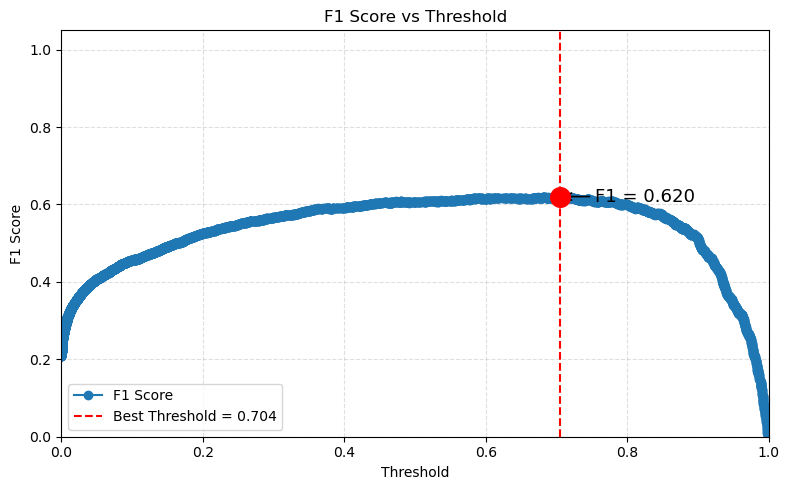

In [27]:
plt.figure(figsize=(8, 5))

# a) Threshold vs F1 Score 곡선
plt.plot(thresholds, f1_scores[:-1],
         linestyle='-',
         marker='o',
         label='F1 Score')

# b) 최적 임계값 위치에 빨간 수직선 추가
plt.axvline(
    x=best_threshold,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Best Threshold = {best_threshold:.3f}'
)

# c) 최적 지점(Threshold, F1)에 빨간 점 표시
plt.scatter(
    best_threshold,
    best_f1,
    color='red',
    s=200,          # 점 크기
    zorder=5       # 그래프 위에 오도록
)

# d) 화살표와 텍스트(annotation) 추가
plt.annotate(
    f"F1 = {best_f1:.3f}",
    xy=(best_threshold, best_f1),               # 화살표 끝나는 위치
    xytext=(best_threshold + 0.05, best_f1),     # 텍스트 위치 (수직선 오른쪽 +0.05)
    arrowprops=dict(arrowstyle="->", lw=1.2),
    fontsize=13,
    va='center'  # 텍스트 수직 정렬: 화살표 끝점과 가운데 맞춤
)

# e) 그래프 꾸미기
plt.title("F1 Score vs Threshold")
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.xlim(0, 1.0)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

ValueError: Found input variables with inconsistent numbers of samples: [30000, 6330]

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# ───────────────────────────────────────────────
# (1) 이미 가지고 있는 변수:
#     df_val_y, y_prob = best_model.predict_proba(df_val_x_selected)[:, 1]
# ───────────────────────────────────────────────

# 1) Precision, Recall, Threshold 계산
precisions, recalls, thresholds = precision_recall_curve(df_val_y, y_prob)

# 2) F1 Score 계산
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 3) 최적 Threshold 및 F1 값 찾기
best_idx    = np.argmax(f1_scores[:-1])      # thresholds[i] ↔ f1_scores[i]
best_threshold = thresholds[best_idx]
best_f1       = f1_scores[best_idx]

print(f"Best Threshold for F1 Score: {best_threshold:.4f}")
print(f"Optimized F1 Score: {best_f1:.4f}")

# ───────────────────────────────────────


Best Threshold for F1 Score: 0.7043
Optimized F1 Score: 0.6205


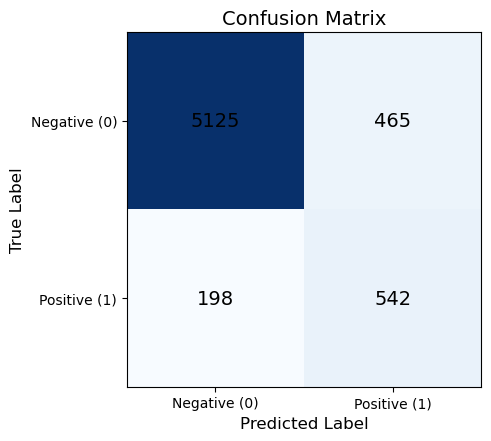


=== Evaluation Metrics ===
   Metric    Value
 Accuracy 0.895261
Precision 0.538232
   Recall 0.732432
 F1 Score 0.620492


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ───────────────────────────────────────────────
# 위에서 이미 구해 둔 변수:
#   df_val_y, y_prob, best_threshold, best_f1
# ───────────────────────────────────────────────

# 4) 최적 Threshold로 y_pred 생성
y_pred = (y_prob >= best_threshold).astype(int)

# 5) Confusion Matrix 계산
cm = confusion_matrix(df_val_y, y_pred)  # [[TN, FP],
                                          #  [FN, TP]]

# 6) Confusion Matrix 시각화
plt.figure(figsize=(5, 5))
plt.imshow(cm, cmap='Blues', interpolation='nearest')
plt.title("Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

# x축, y축 눈금 및 레이블 설정
plt.xticks([0, 1], ['Negative (0)', 'Positive (1)'])
plt.yticks([0, 1], ['Negative (0)', 'Positive (1)'])

# 각 셀에 정수 값 쓰기
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            horizontalalignment='center',
            verticalalignment='center',
            color='black',
            fontsize=14
        )

plt.tight_layout()
plt.show()


# 7) 주요 평가지표 계산
acc      = accuracy_score(df_val_y, y_pred)
prec     = precision_score(df_val_y, y_pred, zero_division=0)
rec      = recall_score(df_val_y, y_pred)
f1       = f1_score(df_val_y, y_pred)

# 8) Pandas DataFrame으로 정리하여 출력
metrics = {
    'Metric':    ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value':     [acc,        prec,        rec,      f1]
}
metrics_df = pd.DataFrame(metrics)

print("\n=== Evaluation Metrics ===")
print(metrics_df.to_string(index=False))


### 5. 모델 평가

In [37]:
# threshold 설정
thres=0.7043

In [38]:
# 훈련 데이터에 대한 성능 평가
y_retrn_pred_proba = best_model.predict_proba(df_retrn_x_selected)[:, 1]
y_retrn_pred_label = (y_retrn_pred_proba > thres).astype(int)

print(f"훈련 데이터 Accuracy: {accuracy_score(df_retrn_y, y_retrn_pred_label)}")
print(f"훈련 데이터 Precision: {precision_score(df_retrn_y, y_retrn_pred_label)}")
print(f"훈련 데이터 Recall: {recall_score(df_retrn_y, y_retrn_pred_label)}")
print(f"훈련 데이터 F1 Score: {f1_score(df_retrn_y, y_retrn_pred_label)}")

훈련 데이터 Accuracy: 0.9304419954970968
훈련 데이터 Precision: 0.6480887792848335
훈련 데이터 Recall: 0.887238352464551
훈련 데이터 F1 Score: 0.7490380504489098


검증 데이터로 성능 평가

In [39]:
# 검증 데이터에 대한 성능 평가
y_val_pred_proba = best_model.predict_proba(df_val_x_selected)[:, 1]
y_val_pred_label = (y_val_pred_proba > thres).astype(int)

print(f"검증 데이터 Accuracy: {accuracy_score(df_val_y, y_val_pred_label)}")
print(f"검증 데이터 Precision: {precision_score(df_val_y, y_val_pred_label)}")
print(f"검증 데이터 Recall: {recall_score(df_val_y, y_val_pred_label)}")
print(f"검증 데이터 F1 Score: {f1_score(df_val_y, y_val_pred_label)}")

검증 데이터 Accuracy: 0.895260663507109
검증 데이터 Precision: 0.5382323733862959
검증 데이터 Recall: 0.7324324324324324
검증 데이터 F1 Score: 0.6204922724670864


### 6. 최종 모델 학습(전체 훈련 데이터)

In [41]:
df_trn_x_selected = df_trn_x[selected_features]
best_model.fit(df_trn_x_selected, df_trn_y)

LGBMClassifier(class_weight='balanced', colsample_bytree=0.6,
               learning_rate=0.15, max_depth=5, min_child_samples=150,
               n_estimators=500, random_state=42, subsample=0.7, verbose=-1)

### 7. 테스트 데이터에 대한 예측 후 저장하기

#### 7.1 테스트데이터에 대한 예측 수행

In [42]:
y_tst_pred_proba = best_model.predict_proba(df_tst_x_selected)[:,1]

In [43]:
y_tst_pred_label = (y_tst_pred_proba > thres).astype(int)

#### 7.2 예측결과 저장하기

In [44]:
df_submission = pd.read_csv('submission_example.csv')

In [45]:
df_submission.head()

,ID,label
0,test00001,0
1,test00002,0
2,test00003,0
3,test00004,0
4,test00005,0


In [46]:
df_submission['label'] = y_tst_pred_label

In [47]:
df_submission['label'].value_counts()

label
0    11473
1     2091
Name: count, dtype: int64

In [48]:
# 다하고 눌러라!!!!
filename = 'LightGBM_Ho_final-1.csv'
df_submission.to_csv(filename, index=False)